In [1]:
import pandas as pd
import re
import numpy as np

# File processing
from pathlib import Path

# Data viz
import seaborn as sns
import matplotlib.pyplot as plt

# Parameters

## Bedtools

In [2]:
from pybedtools import BedTool
from pybedtools.helpers import cleanup as bedtools_cleanup
from pybedtools.helpers import set_tempdir

In [3]:
bedtools_cleanup()

In [4]:
# https://github.com/daler/pybedtools/issues/252
def is_valid_bedtools(a):
    '''Does not work for BedTool from iterable'''
    try:
        ft = a.file_type
        if ft == 'empty':
            print("empty file!")
        else:
            print(f'input is {ft} - OK!')
    except IndexError:
        print('bad input!')

    

In [5]:
def extract_id_gff(x):
    m = re.match(r".*ID=(.*?);", x)
    if m:
        return m.groups()[0]
    else:
        print(x)

In [6]:
def id_filter(feature, ids):
    '''any feature with "ID" in list'''
    return feature.attrs["ID"] in ids

def type_filter(feature, t):
    ''' any features of type t'''
    return feature[2] == t


def not_type_filter(feature, t):
    ''' any features of any type execpt t'''
    return not (feature[2] in t)



## File paths

In [7]:
base_dir = Path("../")
data_dir = base_dir / "raw_data"
parsed_data_dir = base_dir / "parsed_data"
ref_data_dir = Path("../../reference_files/")

#### Bedtools tmpdir

In [8]:
bedtools_tmp = data_dir / "bedtools_tmp"
bedtools_tmp.mkdir(parents=True, exist_ok=True)
set_tempdir(bedtools_tmp)

# Load

In [9]:
gff_columns = [
    "seqname", 
    "source", 
    "feature", 
    "start", 
    "end", 
    "score", 
    "strand", 
    "frame", 
    "attribute"
] 

### Araport

In [10]:
araport_file = ref_data_dir / "Araport11_GFF3_genes_transposons.current_utf8.gff.gz"
araport_gff = BedTool(araport_file)
is_valid_bedtools(araport_gff)
len(araport_gff)

input is gff - OK!


927373

In [11]:
# remove transposons - ignore, does nothing without removing children
# araport_gff = araport_gff\
#         .filter(not_type_filter, "transposable_element")\
#         .filter(not_type_filter, "transposon_fragment")\
#         .filter(not_type_filter, "transposable_element_gene").saveas()

In [12]:
# f_araport = set([feature.attrs['Parent'].split(".")[0] for feature in araport_gff if 'Parent' in feature.attrs])
# print(len(f_araport))

In [13]:
proteins_gff = araport_gff.filter(type_filter, "protein").saveas()
proteins_gff = proteins_gff.sort()

In [14]:
def update_feature_attrs(feature):
    '''Make feature the gene ID and the position of the "TSS" '''

    if feature.strand == "-":
        target = feature.end
    else:
        target = feature.start    
    attrs = f"Note={target};"
    
    feature_id = feature.attrs['ID']
    if feature_id:
        # feature.attrs = f"ID={feature_id};Parent={feature_id.split(':')[0]};"
        # feature.attrs = f"ID={feature_id.split(':')[0]};"
        attrs += f"ID={feature_id.split('.')[0]};"

    feature.attrs  = attrs
    return feature
proteins_gff = proteins_gff.each(update_feature_attrs).saveas()    

In [15]:
# https://github.com/daler/gffutils/blob/32e48a1b2c032cb2442286ec4e198a50e04c5c8c/gffutils/pybedtools_integration.py#L188
from pybedtools.featurefuncs import five_prime
def generate_regulatory_intervals(bed, upstream=0, downstream=1):
    for gene in bed:
        yield five_prime(gene, upstream=upstream, downstream=downstream)

In [86]:
UPSTREAM_LIMIT = 2500
DOWNSTREAM_LIMIT = 2500

araport_tss_region = BedTool(
    generate_regulatory_intervals(proteins_gff, 
                           upstream=UPSTREAM_LIMIT, downstream=DOWNSTREAM_LIMIT)).saveas()


In [87]:
araport_tss_region.head()

Chr1	Araport11	protein	1260	6259	.	+	.	Note=3759;ID=AT1G01010;
 Chr1	Araport11	protein	6167	11166	.	-	.	Note=8666;ID=AT1G01020;
 Chr1	Araport11	protein	5920	10919	.	-	.	Note=8419;ID=AT1G01020;
 Chr1	Araport11	protein	5943	10942	.	-	.	Note=8442;ID=AT1G01020;
 Chr1	Araport11	protein	5943	10942	.	-	.	Note=8442;ID=AT1G01020;
 Chr1	Araport11	protein	6167	11166	.	-	.	Note=8666;ID=AT1G01020;
 Chr1	Araport11	protein	5920	10919	.	-	.	Note=8419;ID=AT1G01020;
 Chr1	Araport11	protein	10441	15440	.	-	.	Note=12940;ID=AT1G01030;
 Chr1	Araport11	protein	10441	15440	.	-	.	Note=12940;ID=AT1G01030;
 Chr1	Araport11	protein	21019	26018	.	+	.	Note=23518;ID=AT1G01040;
 

In [88]:
# def move_feature(feature):
#     '''Make feature the gene ID and the position of the "TSS" '''

#     if feature.strand == "+" or feature.strand ==".":
#         feature.start = max(feature.start - 1000, 0)
#     else:
#         feature.end = feature.end + 1000
#     return feature
# araport_tss_region = araport_tss_region.each(move_feature).saveas()
# araport_tss_region.head()

In [89]:
len(araport_tss_region)

48237

In [90]:
# f_5utr = set([feature.attrs['Parent'].split(".")[0] for feature in araport_tss_region if 'Parent' in feature.attrs])
# print(len(f_5utr))

In [91]:
araport_tss_region_collapsed = araport_tss_region.groupby(
    g = [1, 2, 3, 4, 5, 6, 7, 8],
    c=[9], 
    o=['distinct'], 
    delim=""
).saveas()

In [92]:
araport_tss_region_collapsed.head()

Chr1	Araport11	protein	1260	6259	.	+	.	Note=3759;ID=AT1G01010;
 Chr1	Araport11	protein	6167	11166	.	-	.	Note=8666;ID=AT1G01020;
 Chr1	Araport11	protein	5920	10919	.	-	.	Note=8419;ID=AT1G01020;
 Chr1	Araport11	protein	5943	10942	.	-	.	Note=8442;ID=AT1G01020;
 Chr1	Araport11	protein	6167	11166	.	-	.	Note=8666;ID=AT1G01020;
 Chr1	Araport11	protein	5920	10919	.	-	.	Note=8419;ID=AT1G01020;
 Chr1	Araport11	protein	10441	15440	.	-	.	Note=12940;ID=AT1G01030;
 Chr1	Araport11	protein	21019	26018	.	+	.	Note=23518;ID=AT1G01040;
 Chr1	Araport11	protein	30171	35170	.	-	.	Note=32670;ID=AT1G01050;
 Chr1	Araport11	protein	34562	39561	.	-	.	Note=37061;ID=AT1G01060;
 

In [93]:
len(araport_tss_region_collapsed)

32749

In [94]:
araport_tss_region_collapsed.saveas(parsed_data_dir / f"araport_tss_five_prime_UTR_region_collapsed_{UPSTREAM_LIMIT}-{DOWNSTREAM_LIMIT}.bed")

<BedTool(../parsed_data/araport_tss_five_prime_UTR_region_collapsed_2500-2500.bed)>

In [53]:
# END

## TSS region and peaks

To create figures below (all distances of all peaks to TSS's), rerun above with 

```
UPSTREAM_LIMIT = 10000
DOWNSTREAM_LIMIT = 10000
```

In [54]:
subset = "col"

dapseq_bed_file = parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.bed"
dapseq_bed = BedTool(dapseq_bed_file)
is_valid_bedtools(dapseq_bed)
len(dapseq_bed)

peaks = pd.read_csv(parsed_data_dir / f"{subset}_merged_filtered_dapseq_peaks.tsv", sep="\t", usecols=[4, 10], index_col=0)
def extract_gff_attribute(x, attr="ID"):
    m = re.match(rf".*{attr}=(.*?);", x)
    if m:
        return m.groups()[0]
    else:
        print(x)


def distance_from_tss(x):

    # start / end  = peak start / peak end
    # gff_start / gff_end  = target region start / target region end   
    
    
    strand = x["strand"]
    tss_site = x["tss_site"]
    peak = x["start"] + x["peak"]
    
    if strand == "-":
        return  tss_site - peak 
    
    return peak - tss_site

input is bed - OK!


In [55]:
# https://bedtools.readthedocs.io/en/latest/content/tools/intersect.html
# minimum overlap as fraction of A (dapseq): f=1
dapseq_intersection = dapseq_bed.intersect(araport_tss_region, f=1, wo=True)
print("Done")

print(len(dapseq_intersection))
dapseq_intersection.head(3)

Done
8683228
Chr1	0	290	1:0-MYBrelated_tnt.TRP2_col_a	Chr1	Araport11	protein	1	13759	.	+	.	Note=3759;ID=AT1G01010;	290
 Chr1	0	290	1:0-MYBrelated_tnt.TRP2_col_a	Chr1	Araport11	protein	1	18666	.	-	.	Note=8666;ID=AT1G01020;	290
 Chr1	0	290	1:0-MYBrelated_tnt.TRP2_col_a	Chr1	Araport11	protein	1	18419	.	-	.	Note=8419;ID=AT1G01020;	290
 

In [56]:
df_intersection  = dapseq_intersection.to_dataframe(names=[
    'chrom', 'start', 'end', 'name', # bed
    "seqname", "source", "feature", "gff_start", "gff_end", "score", "strand", "frame", "attributes", # gff
    "overlap"
])

df_intersection = df_intersection.join(peaks, on="name", how="left")

df_intersection["target"] = df_intersection["attributes"].apply(extract_gff_attribute, attr="ID")
df_intersection["tss_site"] = df_intersection["attributes"].apply(extract_gff_attribute, attr="Note")
df_intersection["tss_site"] = df_intersection["tss_site"].apply(int)

In [57]:
df_intersection.shape[0]

8683228

In [58]:
df_intersection.head()

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap,peak,target,tss_site
0,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,protein,1,13759,.,+,.,Note=3759;ID=AT1G01010;,290,19,AT1G01010,3759
1,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,protein,1,18666,.,-,.,Note=8666;ID=AT1G01020;,290,19,AT1G01020,8666
2,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,protein,1,18419,.,-,.,Note=8419;ID=AT1G01020;,290,19,AT1G01020,8419
3,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,protein,1,18442,.,-,.,Note=8442;ID=AT1G01020;,290,19,AT1G01020,8442
4,Chr1,0,290,1:0-MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,protein,1,18442,.,-,.,Note=8442;ID=AT1G01020;,290,19,AT1G01020,8442


In [59]:
del dapseq_bed
del dapseq_intersection

In [60]:
df_intersection.to_csv(parsed_data_dir / f"{subset}_all_distances.tsv", sep="\t", index=False)

In [61]:
df_intersection["distance"] = df_intersection.apply(distance_from_tss, axis=1)

<Axes: xlabel='distance', ylabel='Count'>

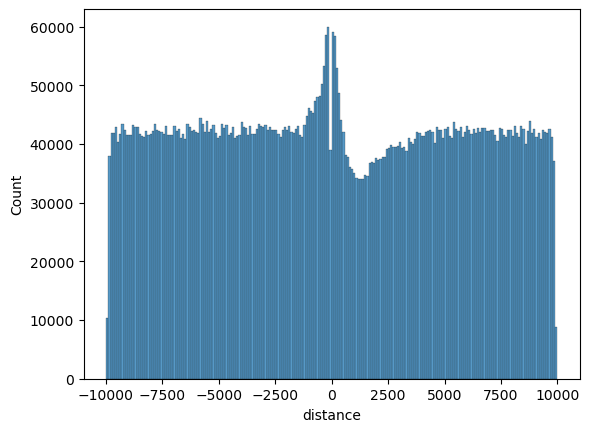

In [62]:
# per peak, the distance to all TSS
sns.histplot(df_intersection["distance"])

<Axes: xlabel='distance', ylabel='Count'>

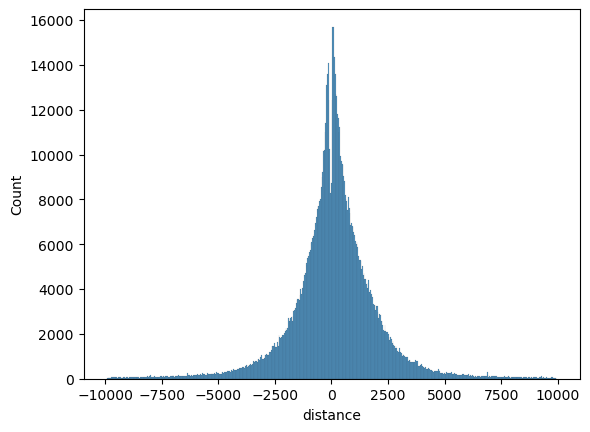

In [83]:
# per peak, the closest TSS
df_intersection = df_intersection.loc[
             df_intersection.groupby('name')['distance'].apply(lambda x: x.abs().idxmin())
]

sns.histplot(df_intersection["distance"])

(-1000.0, 1000.0)

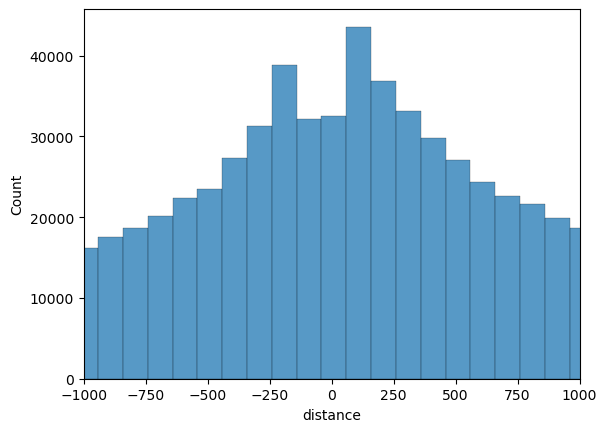

In [84]:
sns.histplot(df_intersection["distance"], binwidth=100)
plt.xlim([-1000, 1000])

In [ ]:
from scipy.signal import savgol_filter

Text(0.5, 0, '# Distance from target')

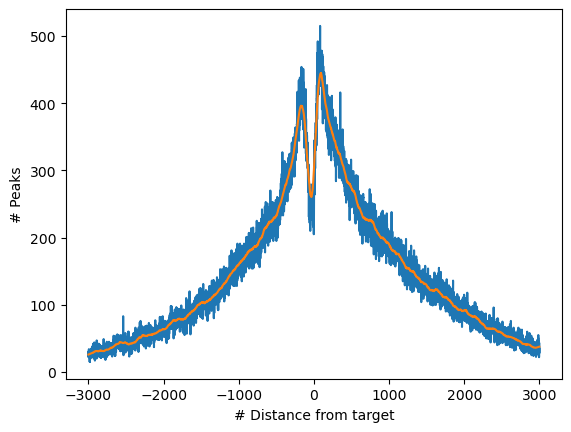

In [85]:
xlim = 3000
r = []
for i in range(-xlim, xlim): 
    df = df_intersection[df_intersection["distance"]==i]
    r.append(df.shape[0])

yhat = savgol_filter(r, 100, 1) # window size 51, polynomial order 3
plt.plot(range(-xlim, xlim), r)
plt.plot(range(-xlim, xlim), yhat)

plt.ylabel("# Peaks")
plt.xlabel("# Distance from target")

In [43]:
df_intersection.to_csv("not-collapsed.tsv", sep="\t")

<Axes: xlabel='distance', ylabel='Count'>

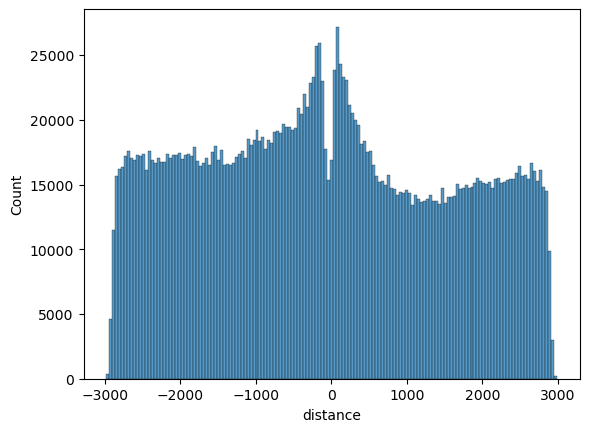

In [44]:
sns.histplot(df_intersection["distance"])

<Axes: xlabel='distance', ylabel='Count'>

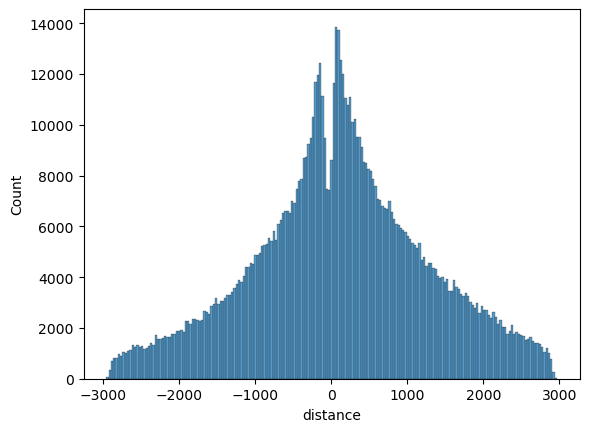

In [52]:
sns.histplot(df_intersection.loc[
             df_intersection.groupby('name')['distance'].apply(lambda x: x.abs().idxmin())
]["distance"])

<Axes: xlabel='distance', ylabel='Count'>

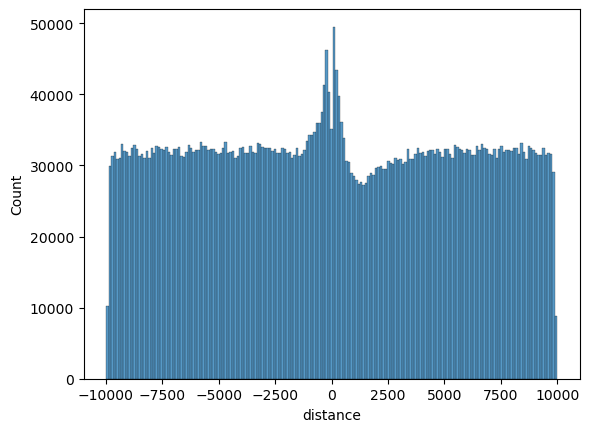

In [102]:
sns.histplot(df_intersection[
    df_intersection["start"] - df_intersection["end"] <2000
]["distance"])

(-1000.0, 1000.0)

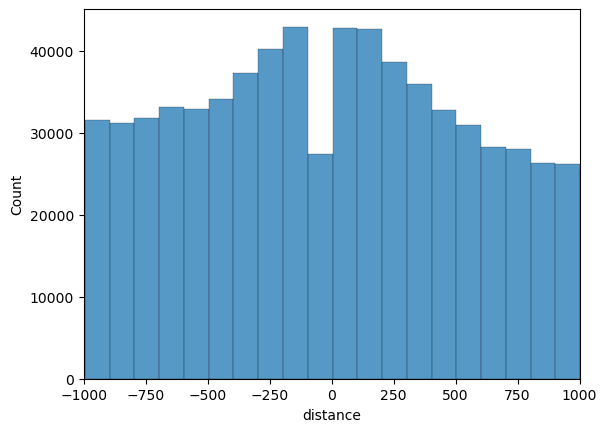

In [121]:
sns.histplot(df_intersection["distance"], binwidth=100)
plt.xlim([-1000, 1000])

In [122]:
r = []
for i in range(-1000, 1000): 
    df = df_intersection[df_intersection["distance"]==i]
    r.append(df.shape[0])
    # if df.shape[0] < 250:
    #     print(i, df.shape[0])

Text(0.5, 0, '# Distance from target')

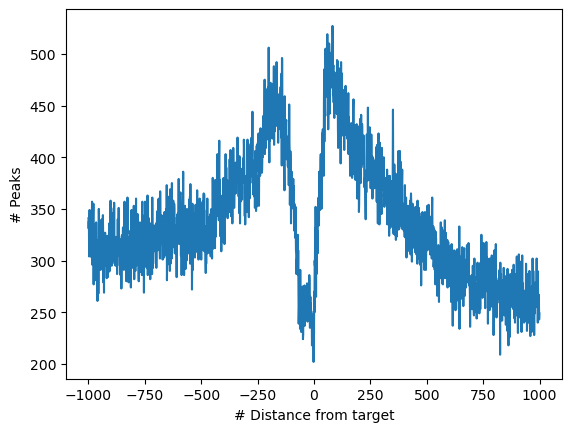

In [124]:
xlim = 1000
r = []
for i in range(-xlim, xlim): 
    df = df_intersection[df_intersection["distance"]==i]
    r.append(df.shape[0])
    # if df.shape[0] < 250:
 

plt.plot(range(-xlim, xlim), r)
plt.ylabel("# Peaks")
plt.xlabel("# Distance from target")

input is bed - OK!


998130

In [27]:
peaks = pd.read_csv(data_dir / parsed_data_dir / "merged_filtered_col_dapseq_peaks.tsv", sep="\t", usecols=[4, 10], index_col=0)
def extract_gff_attribute(x, attr="ID"):
    m = re.match(rf".*{attr}=(.*?);", x)
    if m:
        return m.groups()[0]
    else:
        print(x)



In [31]:
dapseq_bed_file = data_dir / parsed_data_dir / "merged_filtered_col_dapseq_peaks.bed"
dapseq_bed = BedTool(dapseq_bed_file)
is_valid_bedtools(dapseq_bed)
len(dapseq_bed)

def distance_from_tss(x):

    # start / end  = peak start / peak end
    # gff_start / gff_end  = target region start / target region end   
    
    
    strand = x["strand"]
    tss_site = x["tss_site"]
    peak = x["start"] + x["peak"]
    
    if strand == "-":
        return  tss_site - peak 
    
    return peak - tss_site

In [36]:
# def repare_feature_attributes(feature):
#     try:
#         d = {
#             "ID":set(),
#             "Note":set()
#         }
        
#         for attr in feature[8].split(";"):
#             label, value = attr.split("=", 1)
#             if label=="ID":
#                 d["ID"].update([value])
#             if label=="Note":
#                 d["Note"].update([value])
#         parent = {x.split(":")[0] for x in d["ID"]}
#         if len(parent) != 1:
#             print("multiple parents", parent, "\n", feature)
#         d["Parent"] = parent.pop()
#         d["ID"] = ','.join(d["ID"])
#         d["Note"] = ','.join(d["Note"])
        
#         feature.attrs = d
#     except Exception as e:
#         print(feature[8])
#         raise e
        
#     return feature


# def add_gene_id(feature):
#     gene_id = ""
#     feature_id = feature.attrs['ID']
#     if feature_id:
#         feature.attrs['gene_ID'] = feature_id.split(":")[0]
#         # feature.attrs = f"ID={feature_id.split(':')[0]};"
#     return feature
    
# araport_tss_region_gene = araport_tss_region.each(add_gene_id).saveas()

# df_collapse = araport_tss_region_gene.groupby(
#     g = [9],
#     c=[1,        2,      3,       4,     5,      6,       7,       8,       9,        9], 
#     o=['first', 'first', 'first', 'min', 'max', 'first', 'first', 'first', 'first', 'count']
# ).to_dataframe(names=["features"] + gff_columns + ["count"]).sort_values("count")

# df_collapse['len'] = df_collapse['end'] - df_collapse['start']

# sns.relplot(
#     data=df_collapse, 
#     x='count', y='len')
# plt.ylabel("Length of collapsed region")
# plt.xlabel("# 5'UTR regions per gene")

## Intersection with TSS "region"

In [140]:
# https://bedtools.readthedocs.io/en/latest/content/tools/intersect.html
# minimum overlap as fraction of A (dapseq): f=1
dapseq_intersection = dapseq_bed.intersect(araport_tss_region, f=1, wo=True)
print(len(dapseq_intersection))
dapseq_intersection.head(3)

2084193
Chr1	0	166	1:65_MYBrelated_tnt.TRP2_col_a	Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	166
 Chr1	0	181	1:80_MYBrelated_tnt.TRP1_col	Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	181
 Chr1	0	161	1:60_MYBrelated_tnt.AT1G72740_col_a	Chr1	Araport11	gene	1	8630	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxre

In [141]:
df_intersection  = dapseq_intersection.to_dataframe(names=[
    'chrom', 'start', 'end', 'name', # bed
    "seqname", "source", "feature", "gff_start", "gff_end", "score", "strand", "frame", "attributes", # gff
    "overlap"
])

In [142]:
df_intersection.head()

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap
0,Chr1,0,166,1:65_MYBrelated_tnt.TRP2_col_a,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,166
1,Chr1,0,181,1:80_MYBrelated_tnt.TRP1_col,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,181
2,Chr1,0,161,1:60_MYBrelated_tnt.AT1G72740_col_a,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,161
3,Chr1,104,305,1:204_MYBrelated_tnt.EPR1_col,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,201
4,Chr1,105,306,1:205_MYBrelated_tnt.LHY1_col_a,Chr1,Araport11,gene,1,8630,.,+,.,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,201


In [143]:
len(set(df_intersection["name"]))

657563

In [144]:
df_intersection.shape

(2084193, 14)

In [145]:
df_intersection.groupby("name").size().value_counts()

3     179025
2     157600
4     135763
1      75530
5      68453
6      26489
7       9479
8       3222
9       1186
10       411
12       126
11       123
13        52
16        25
17        23
14        19
18        17
15        15
19         5
Name: count, dtype: int64

In [147]:
df_intersection["target"] = df_intersection["attributes"].apply(extract_id_gff)

In [148]:
df_intersection.tail()

,chrom,start,end,name,seqname,source,feature,gff_start,gff_end,score,strand,frame,attributes,overlap,target
2084188,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,Araport11,gene,26966389,26976388,.,+,.,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,201,AT5G09955
2084189,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,Araport11,gene,26967645,26977644,.,-,.,ID=AT5G09965;Name=AT5G09965;locus_type=long_no...,201,AT5G09965
2084190,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,Araport11,gene,26965669,26975668,.,-,.,ID=AT5G67640;Name=AT5G67640;Dbxref=TAIR:215866...,201,AT5G67640
2084191,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,Araport11,gene,26966389,26976388,.,+,.,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,201,AT5G09955
2084192,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,Araport11,gene,26967645,26977644,.,-,.,ID=AT5G09965;Name=AT5G09965;locus_type=long_no...,201,AT5G09965


## Closest TSS per peak only

__This is done extradinarily inefficiently... __

Closest is not the abosulte closest, because the acutal closest may not have the peak in its "region". 

Would be waaaay easier of we only did upstream or only downstream (bedtool closest function). 

Or upstream and downstream seperately, and prioritise after?

In [149]:
def name_filter(feature, l):
    return feature.attrs["ID"] in l


In [150]:
df_intersection = df_intersection[['chrom', 'start', 'end', 'name', 
                                   'seqname', 'strand', 'overlap', 'target']]

In [151]:
df_tss = pd.DataFrame(araport_tss.filter(name_filter, l=list(set(df_intersection["target"]))).saveas().to_dataframe()[["start", "attributes"]])
df_tss.shape

(32714, 2)

In [152]:
df_tss.columns = ["tss_site", "target_attributes"]

In [153]:
df_tss["ID"] = df_tss["target_attributes"].apply(extract_id_gff)

In [154]:
df_tss.head()

,tss_site,target_attributes,ID
0,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,AT1G01010
1,9130,ID=AT1G01020;Name=AT1G01020;computational_desc...,AT1G01020
2,11101,ID=AT1G03987;Name=AT1G03987;locus_type=long_no...,AT1G03987
3,13714,ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;...,AT1G01030
4,23121,ID=AT1G01040;Name=AT1G01040;full_name=dicer-li...,AT1G01040


In [155]:
df_intersection = df_intersection.join(df_tss.set_index("ID"), on="target", how="left")


In [156]:
df_intersection.head()

,chrom,start,end,name,seqname,strand,overlap,target,tss_site,target_attributes
0,Chr1,0,166,1:65_MYBrelated_tnt.TRP2_col_a,Chr1,+,166,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
1,Chr1,0,181,1:80_MYBrelated_tnt.TRP1_col,Chr1,+,181,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
2,Chr1,0,161,1:60_MYBrelated_tnt.AT1G72740_col_a,Chr1,+,161,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
3,Chr1,104,305,1:204_MYBrelated_tnt.EPR1_col,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
4,Chr1,105,306,1:205_MYBrelated_tnt.LHY1_col_a,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...


In [157]:
def distance_from_tss(x):
    strand = x["strand"]

    # overlaps
    if x["start"] <= x["tss_site"] <= x["end"]:
        return 0
    
    if strand == "+" or strand == ".":
        
        # peak is upstream, take tss - peak_end
        if x["end"] < x["tss_site"]:
            return x["end"] - x["tss_site"]
        
        # peak is downstream, take peak_start - tss
        elif x["start"] > x["tss_site"]:
            return x["start"] - x["tss_site"]

        # shouldn be here
        else:
            return pd.NA

    else:
        
        # peak is downstream, take tss - peak_end
        if x["end"] < x["tss_site"]:
            return x["tss_site"] - x["end"]
        
        # peak is upstream, take peak_start - tss
        elif x["start"] > x["tss_site"]:
            return x["tss_site"] - x["start"]

        # shouldn be here
        else:
            return pd.NA


        
    

In [158]:
df_intersection["distance"] = df_intersection.apply(distance_from_tss, axis=1)

In [159]:
df_intersection

,chrom,start,end,name,seqname,strand,overlap,target,tss_site,target_attributes,distance
0,Chr1,0,166,1:65_MYBrelated_tnt.TRP2_col_a,Chr1,+,166,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3465
1,Chr1,0,181,1:80_MYBrelated_tnt.TRP1_col,Chr1,+,181,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3450
2,Chr1,0,161,1:60_MYBrelated_tnt.AT1G72740_col_a,Chr1,+,161,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3470
3,Chr1,104,305,1:204_MYBrelated_tnt.EPR1_col,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3326
4,Chr1,105,306,1:205_MYBrelated_tnt.LHY1_col_a,Chr1,+,201,AT1G01010,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...,-3325
...,...,...,...,...,...,...,...,...,...,...,...
2084188,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,+,201,AT5G09955,26971389,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,3926
2084189,Chr5,26975315,26975516,5:26975415_MYBrelated_tnt.TRP2_col_a,Chr5,-,201,AT5G09965,26972644,ID=AT5G09965;Name=AT5G09965;locus_type=long_no...,-2671
2084190,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,-,201,AT5G67640,26970668,ID=AT5G67640;Name=AT5G67640;Dbxref=TAIR:215866...,-4654
2084191,Chr5,26975322,26975523,5:26975422_MYBrelated_tnt.AT1G72740_col_a,Chr5,+,201,AT5G09955,26971389,ID=AT5G09955;Name=AT5G09955;locus_type=long_no...,3933


<Axes: xlabel='distance', ylabel='Count'>

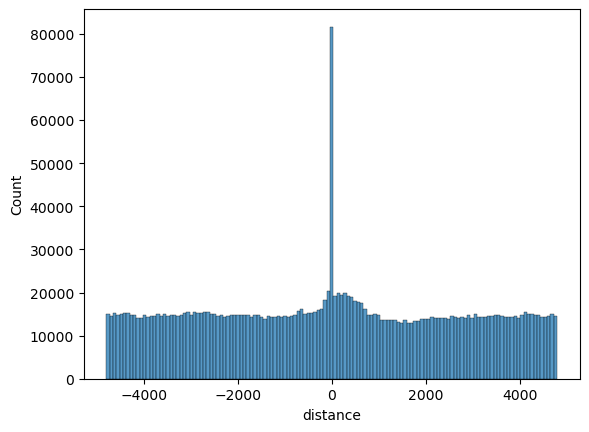

In [161]:
sns.histplot(df_intersection["distance"])

<Axes: xlabel='distance', ylabel='Count'>

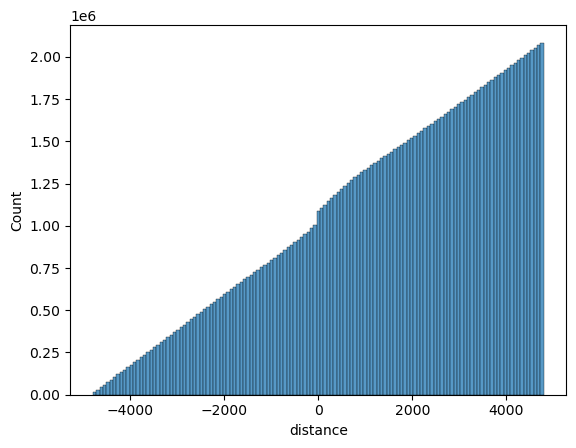

In [162]:
sns.histplot(df_intersection["distance"], cumulative=True)

In [179]:
df_intersection_min_per_peak = df_intersection.loc[df_intersection.groupby('name')['distance'].apply(lambda x: x.abs().idxmin())]

<Axes: xlabel='distance', ylabel='Count'>

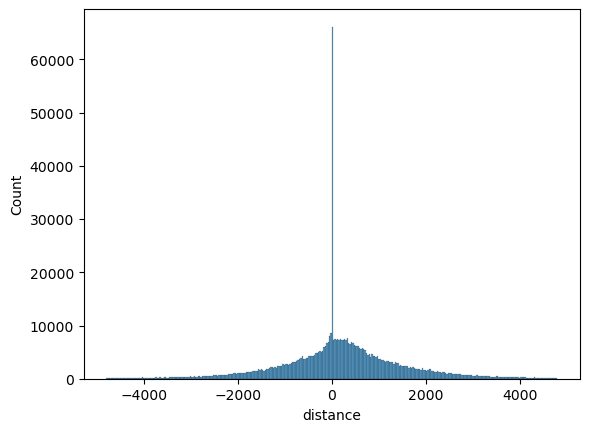

In [180]:
sns.histplot(df_intersection_min_per_peak["distance"])

<Axes: xlabel='distance', ylabel='Count'>

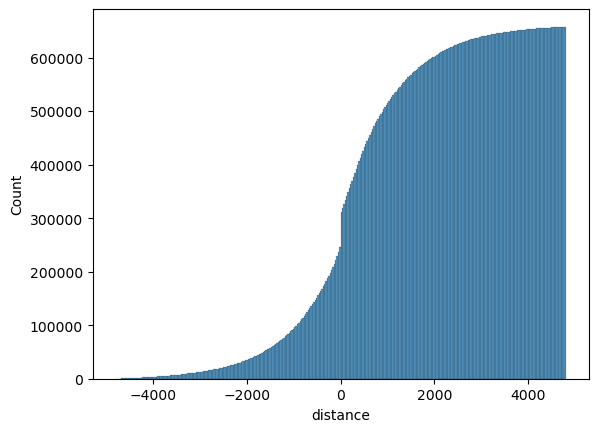

In [181]:
sns.histplot(df_intersection_min_per_peak["distance"], cumulative=True)

<Axes: xlabel='distance', ylabel='Percent'>

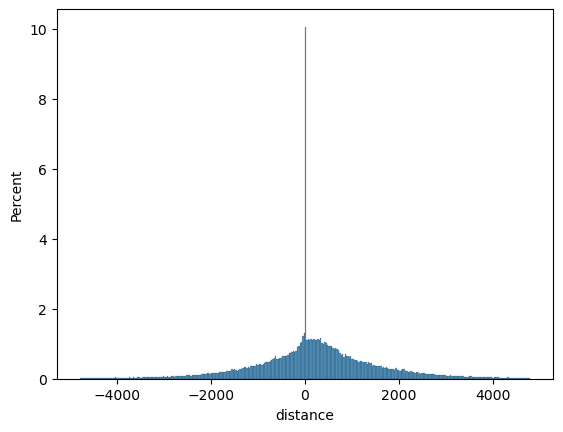

In [182]:
sns.histplot(df_intersection_min_per_peak["distance"], stat="percent")

(0.0, 1.5)

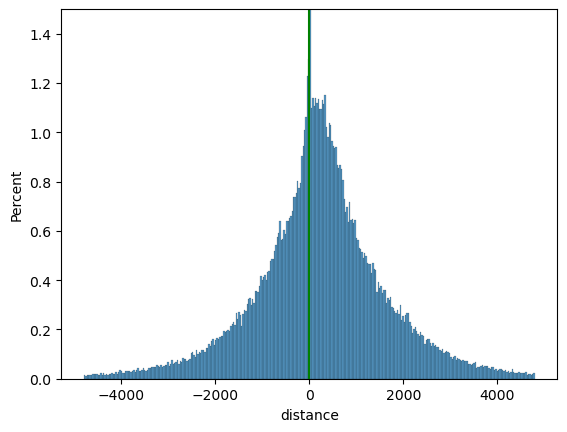

In [186]:
sns.histplot(df_intersection_min_per_peak["distance"], stat="percent")
plt.axvline(0, c="g")
plt.ylim([0, 1.5])

In [192]:
def apply_threshold(x, upstream, downstream):
    return upstream < x < downstream
    

In [193]:
df_intersection_min_per_peak_threshold = df_intersection[df_intersection['distance'].apply(apply_threshold, upstream=-2000, downstream=1000)]

<Axes: xlabel='distance', ylabel='Percent'>

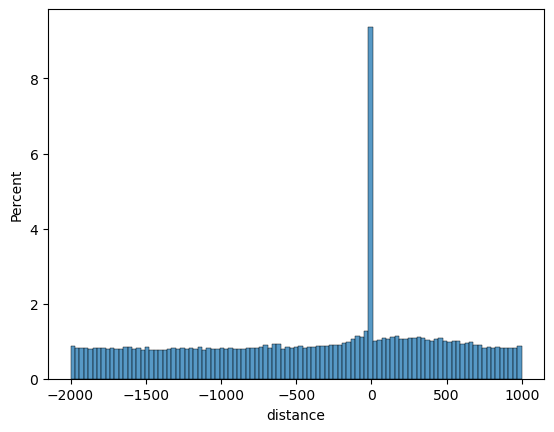

In [194]:
sns.histplot(df_intersection_min_per_peak_threshold["distance"], stat="percent")

(0.0, 1.5)

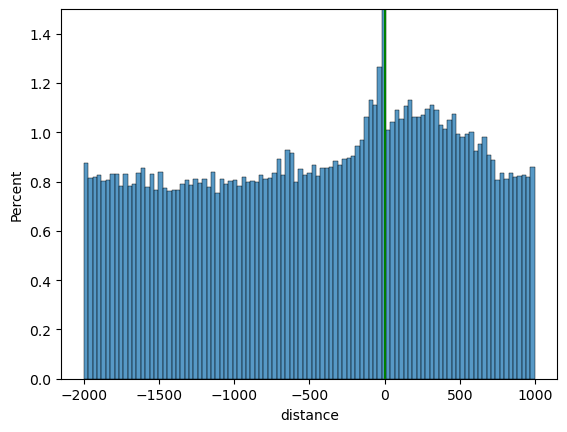

In [198]:
sns.histplot(df_intersection_min_per_peak_threshold["distance"], stat="percent")
plt.axvline(0, c="g")
plt.ylim([0, 1.5])

In [214]:
df_intersection_min_per_peak_threshold.shape

(740454, 11)

## Save results

In [205]:
df_intersection_min_per_peak_threshold.columns

Index(['chrom', 'start', 'end', 'name', 'seqname', 'strand', 'overlap',
       'target', 'tss_site', 'target_attributes', 'distance'],
      dtype='object')

In [208]:
sub_df.columns

Index(['chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand',
       'signalValue', 'pValue', 'qValue', 'peak', 'common title',
       'dna source'],
      dtype='object')

In [232]:
final_df = df_intersection_min_per_peak_threshold[["name", "target", "distance"]].set_index("name").join(
    sub_df[['name', 'signalValue', 'pValue', 'qValue', 'common title']].set_index('name'), 
    how="left"
)
final_df.reset_index(inplace=True)
final_df.head()

,name,target,distance,signalValue,pValue,qValue,common title
0,1:1539_bHLH_tnt.BIM2_col_v3b,AT1G01010,-1991,717.0,0.0,999.00,bHLH_tnt.BIM2_col_v3b
1,1:2126_WRKY_tnt.WRKY33_col_a,AT1G01010,-1404,77.0,0.0,39.72,WRKY_tnt.WRKY33_col_a
2,1:2341_MYBrelated_tnt.At1g49010_col_a,AT1G01010,-1189,109.0,0.0,45.40,MYBrelated_tnt.At1g49010_col_a
3,1:2566_C2C2dof_tnt.AT2G28810_col_a,AT1G01010,-964,240.0,0.0,138.02,C2C2dof_tnt.AT2G28810_col_a
4,1:2570_C2C2dof_tnt.OBP3_col_a,AT1G01010,-960,91.9,0.0,53.16,C2C2dof_tnt.OBP3_col_a


In [233]:
sample_df.columns

Index(['gene id', 'dna source', 'summary', 'taxon', 'protein',
       'protein family', 'protein affinity tag', 'expression system',
       'replicate', 'title', 'accession', 'file_name'],
      dtype='object')

In [234]:
final_df = final_df.join(sample_df[['gene id', 'dna source', 'protein',
       'protein family', 'protein affinity tag', 'expression system',
       'accession']], on="common title", how="left") 

In [235]:
final_df.columns

Index(['name', 'target', 'distance', 'signalValue', 'pValue', 'qValue',
       'common title', 'gene id', 'dna source', 'protein', 'protein family',
       'protein affinity tag', 'expression system', 'accession'],
      dtype='object')

In [236]:
final_df.columns = ['peak_name', 'target', 'peak_distance_tss', 'peak_signalValue', 'peak_pValue',
       'peak_qValue', 'library title', 'tf', 'dna source', 'tf protein', 'tf protein family', 'protein affinity tag',
       'expression system', 'accession']

In [237]:
final_df = final_df[['tf', 'target', 'peak_name', 'peak_distance_tss', 'peak_signalValue', 'peak_pValue',
       'peak_qValue', 'library title', 'tf', 'dna source', 'tf protein', 'tf protein family', 'protein affinity tag', 'expression system', 'accession']]

In [239]:
final_df.head()

,tf,target,peak_name,peak_distance_tss,peak_signalValue,peak_pValue,peak_qValue,library title,tf,dna source,tf protein,tf protein family,protein affinity tag,expression system,accession
0,AT1G69010,AT1G01010,1:1539_bHLH_tnt.BIM2_col_v3b,-1991,717.0,0.0,999.00,bHLH_tnt.BIM2_col_v3b,AT1G69010,col,BIM2,bHLH,Halo,tnt,GSM1925749
1,AT2G38470,AT1G01010,1:2126_WRKY_tnt.WRKY33_col_a,-1404,77.0,0.0,39.72,WRKY_tnt.WRKY33_col_a,AT2G38470,col,WRKY33,WRKY,Halo,tnt,GSM1925711
2,AT1G49010,AT1G01010,1:2341_MYBrelated_tnt.At1g49010_col_a,-1189,109.0,0.0,45.40,MYBrelated_tnt.At1g49010_col_a,AT1G49010,col,At1g49010,MYBrelated,Halo,tnt,GSM1925505
3,AT2G28810,AT1G01010,1:2566_C2C2dof_tnt.AT2G28810_col_a,-964,240.0,0.0,138.02,C2C2dof_tnt.AT2G28810_col_a,AT2G28810,col,AT2G28810,C2C2dof,Halo,tnt,GSM1925171
4,AT3G55370,AT1G01010,1:2570_C2C2dof_tnt.OBP3_col_a,-960,91.9,0.0,53.16,C2C2dof_tnt.OBP3_col_a,AT3G55370,col,OBP3,C2C2dof,Halo,tnt,GSM1925195


In [240]:
final_df.to_csv(parsed_data_dir / "dapseq_2000-1000_75.tsv", sep="\t", index=None)

In [241]:
# END

In [65]:
bedtools_cleanup()

In [66]:
araport_file = ref_data_dir / "Araport11_GFF3_genes_transposons.current_utf8_genes.gff.gz"
araport_gff = BedTool(araport_file)
is_valid_bedtools(araport_gff)
araport_gff = araport_gff.sort()
len(araport_gff)

input is gff - OK!


33243

In [67]:
araport_tss = BedTool(generate_tss_intervals(araport_gff))
araport_tss = araport_tss.sort()
araport_tss.head(1)

Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding
 

In [68]:
araport_tss.TEMPFILES = list(araport_tss.TEMPFILES)

In [73]:
def my_bedtools_cleanup(tmp_dir, keep_files=None):
    if keep_files is None:
        keep_files = []
    else:
        keep_files = [Path(x).name for x in keep_files]

    for f in tmp_dir.glob("pybedtools*"):
        if not (f.name in keep_files):
            f.unlink(missing_ok=True)


In [74]:
my_bedtools_cleanup(bedtools_tmp, keep_files=araport_tss.TEMPFILES)

In [36]:
# https://bedtools.readthedocs.io/en/latest/content/tools/intersect.html
# minimum overlap as fraction of A (dapseq): f=1
dapseq_intersection = dapseq_bed.intersect(araport_tss_region, f=1, wo=True)
print(len(dapseq_intersection))
dapseq_intersection.head(3)

2506288
Chr1	779	965	1:779-WRKY_tnt.WRKY22_col	Chr1	Araport11	protein	760	6759	.	+	.	Note=3759;ID=AT1G01010;	186
 Chr1	922	991	1:922-C2C2dof_tnt.AT1G47655_col_a	Chr1	Araport11	protein	760	6759	.	+	.	Note=3759;ID=AT1G01010;	69
 Chr1	1136	1246	1:1136-C2C2dof_tnt.AT5G66940_col_a	Chr1	Araport11	protein	760	6759	.	+	.	Note=3759;ID=AT1G01010;	110
 

In [75]:
def name_filter(feature, l):
    return feature.attrs["ID"] in l

def get_closest(peak_df, tss=None): 
    list_of_ids = peak_df["target"].to_list()

    if (list_of_ids) == 1:
        for x in BedTool([
                peak_df[["chrom", "start", "end", "name"]].iloc[0].values
            ]).absolute_distance(araport_tss.filter(name_filter, l=list_of_ids)):
            result = list_of_ids[0], x
    else:
        for x in BedTool([
                peak_df[["chrom", "start", "end", "name"]].iloc[0].values
            ]).closest(
                araport_tss.filter(name_filter, l=list_of_ids), D="b"
            ):
            result = extract_id_gff(x.fields[-2]), x.fields[-1]
    
    global i
    i += 1
    if i % 20 == 0:
        my_bedtools_cleanup(bedtools_tmp, keep_files=araport_tss.TEMPFILES)
        
    return pd.Series(result)

In [76]:
i = 0
closest_and_distances = df_intersection.groupby("name").apply(get_closest, tss=araport_tss, include_groups=True)

KeyboardInterrupt: 

In [ ]:
closest_and_distances.columns = ["target", "distance"]
closest_and_distances.to_csv(parsed_data_dir / "tf_target_3000_100.tsv", sep="\t")

In [ ]:
for name, peak_df in df_intersection.head(2000).groupby("name"):
    if peak_df.shape[0] > 1:
        list_of_ids = peak_df["target ID"].to_list()
        break

1:10003433_AP2EREBP_tnt.CBF1_col_a AT1G28450 -346


In [263]:
x.fields

['Chr1',
 '10003333',
 '10003534',
 'AT1G28450',
 'Chr1',
 'Araport11',
 'gene',
 '10003880',
 '10003880',
 '.',
 '+',
 '.',
 'ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-like 58;computational_description=AGAMOUS-like 58;locus=2032543;locus_type=protein_coding;symbol=AGL58;Note=AGAMOUS-like 58;Dbxref=TAIR:2032543;',
 '-346']

In [ ]:
list_of_ids = peak_df["target ID"].to_list()
araport_tss.filter(name_filter, l=list_of_ids).closest()

In [194]:
; list_of_ids

['AT1G28450', 'AT1G28460']

In [195]:
araport_tss.file_type

'gff'

In [168]:
for feature in araport_tss:
    break

In [184]:
feature.attrs.keys()

dict_keys(['ID', 'Name', 'full_name', 'computational_description', 'locus', 'locus_type', 'symbol', 'Note', 'Dbxref'])

In [175]:
feature.attrs["ID"] in list_of_ids

False

<BedTool(/tmp/pybedtools.haemrkev.tmp)>

In [120]:
BedTool(peak_df).closest(araport_tss.filter(lambda x: x.attrs["ID"] in peak_df["target ID"]))

BEDToolsError: 
Command was:

	bedtools closest -b "" -a stdin

Error message was:
Error: Unable to open file . Exiting.


<BedTool(<generator object BedTool.filter.<locals>.<genexpr> at 0x7f8e315c69d0>)>

,start,attributes
0,3631,ID=AT1G01010;Name=AT1G01010;full_name=NAC doma...
1,9130,ID=AT1G01020;Name=AT1G01020;computational_desc...
2,11101,ID=AT1G03987;Name=AT1G03987;locus_type=long_no...
3,13714,ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;...
4,23121,ID=AT1G01040;Name=AT1G01040;full_name=dicer-li...
...,...,...
33238,321438,ID=ATMG00800;Name=trnE(TTC);Note=None;locus_ty...
33239,321945,ID=ATMG00780;Name=trnS(GCT);Note=None;locus_ty...
33240,330773,ID=ATMG00735;Name=cox3;locus_type=protein_coding
33241,346454,ID=ATMG00700;Name=trnK(TTT);Note=None;locus_ty...


In [70]:
df_intersection.groupby("name").size().value_counts()

1     288945
2     123401
3      26156
4       3698
5        558
6        133
7         59
8         40
9          4
10         2
Name: count, dtype: int64

In [362]:
# dapseq_closest = dapseq_intersection.closest(araport_tss, wo=True, D='b', k=15)

In [363]:
dapseq_closest.head()

Chr1	1319	1520	1:1419_MYB_tnt.MYB27_col_a	Chr1	Araport11	gene	1131	3730	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	201	Chr1	Araport11	gene	3631	3631	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	-2111
 Chr1	1319	1520	1:1419_MYB_tnt.MYB27_col_a	Chr1	Araport11	gene	1131	3730	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	20

In [365]:
df_closest  = dapseq_closest.to_dataframe(names=\
    ['chrom', 'start', 'end', 'name'] +\
    [f"{x}_intersection" for x in gff_columns]+\
    ["overlap"] +\
    [f"{x}_closest" for x in gff_columns]+\
    ["distance"]
)
df_closest.shape

ParserError: Error tokenizing data. C error: Expected 24 fields in line 4324271, saw 46


In [366]:
del df_closest

In [ ]:
len(set(df_closest["name"]))

In [358]:
df_closest = df_closest[df_closest["attribute_closest"] == df_closest["attribute_intersection"]]
df_closest.shape

(341211, 24)

In [359]:
df_closest.sort_values('distance', key=abs).groupby('name').first()

,chrom,start,end,seqname_intersection,source_intersection,feature_intersection,gff_start_intersection,gff_end_intersection,score_intersection,strand_intersection,...,seqname_closest,source_closest,feature_closest,gff_start_closest,gff_end_closest,score_closest,strand_closest,frame_closest,attribute_closest,distance
name,,,,,,,,,,,,,,,,,,,,,
1:10001682_NAC_tnt.ANAC034_col,Chr1,10001582,10001783,Chr1,Araport11,gene,10001380,10003979,.,+,...,Chr1,Araport11,gene,10003880,10003880,.,+,.,ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-...,-2097.0
1:10003433_AP2EREBP_tnt.CBF1_col_a,Chr1,10003333,10003534,Chr1,Araport11,gene,10001380,10003979,.,+,...,Chr1,Araport11,gene,10003880,10003880,.,+,.,ID=AT1G28450;Name=AT1G28450;full_name=AGAMOUS-...,-346.0
1:1000565_C2H2_tnt.AT4G26030_col_a,Chr1,1000465,1000666,Chr1,Araport11,gene,998616,1001215,.,+,...,Chr1,Araport11,gene,1001116,1001116,.,+,.,ID=AT1G03920;Name=AT1G03920;computational_desc...,-450.0
1:1000768_C2C2dof_tnt.AT5G66940_col_a,Chr1,1000668,1000869,Chr1,Araport11,gene,998616,1001215,.,+,...,Chr1,Araport11,gene,1001116,1001116,.,+,.,ID=AT1G03920;Name=AT1G03920;computational_desc...,-247.0
1:10008632_CPP_tnt.SOL1_col,Chr1,10008532,10008733,Chr1,Araport11,gene,10007624,10010223,.,+,...,Chr1,Araport11,gene,10010124,10010124,.,+,.,ID=AT1G28470;Name=AT1G28470;full_name=NAC doma...,-1391.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4:995222_NAC_tnt.VND1_col_a,Chr4,995122,995323,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2084.0
4:995222_bHLH_tnt.BIM2_col_v3b,Chr4,995122,995323,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2084.0
4:995223_NAC_tnt.ANAC070_col,Chr4,995123,995324,Chr4,Araport11,gene,992940,995539,.,-,...,Chr4,Araport11,gene,993039,993039,.,-,.,ID=AT4G02270;Name=AT4G02270;full_name=root hai...,-2085.0


In [132]:
# https://daler.github.io/pybedtools/autodocs/pybedtools.bedtool.BedTool.closest.html
# For each feature in A, finds the closest feature (upstream or downstream) in B.
# 's=False' ignore strand, 
# 'D=b' Report the closest feature in B, and its distance to A as an extra column. Use negative distances to report upstream features.
# Report distance with respect to B, when B is on the - strand, "upstream" means A has a higher (start,stop).
b = dapseq_bed.closest(araport_gff, s=False, D="b")
b.head(5)

Chr1	105	306	1:205	Chr1	Araport11	gene	3631	5899	.	+	.	ID=AT1G01010;Name=AT1G01010;full_name=NAC domain containing protein 1;computational_description=NAC domain containing protein 1;locus=2200935;locus_type=protein_coding;symbol=NAC001;Note=NAC domain containing protein 1;Dbxref=TAIR:2200935;locus_type=protein_coding	-3325
 Chr1	7301	7502	1:7401	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	0
 Chr1	8033	8234	1:8133	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	0
 Chr1	16227	16428	1:16327	Chr1	Araport11	gene	11649	13714	.	-	.	ID=AT1G01030;Name=AT1G01030;full_name=NGATHA3;computational_description=AP2/B3-like transcriptiona

In [102]:
len(b)

25877

In [133]:
b.count()

18703

In [134]:
b.field_count()

14

In [138]:
from pybedtools.featurefuncs import five_prime

In [139]:
five_prime(araport_gff)

TypeError: Argument 'feature' has incorrect type (expected pybedtools.cbedtools.Interval, got BedTool)

In [135]:
# Intergenic peaks
# Report overlaps between two feature files. A.intersect(B)
# 'wo' Write the original A and B entries plus the number of base pairs of overlap between the two features. 
#      Overlaps restricted by -f and -r. Only A features with overlap are reported.
# 'F=' Minimum overlap required as a fraction of B.
intergenic_obj = dapseq_bed.intersect(araport_gff, wo=True)
intergenic_obj.head(3)

Chr1	7301	7502	1:7401	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	201
 Chr1	8033	8234	1:8133	Chr1	Araport11	gene	6788	9130	.	-	.	ID=AT1G01020;Name=AT1G01020;computational_description=ARV1 family protein;locus=2200940;locus_type=protein_coding;symbol=ARV1;Note=Arv1-like protein;Dbxref=TAIR:2200940;locus_type=protein_coding	201
 Chr1	66701	66902	1:66801	Chr1	Araport11	gene	64166	67774	.	-	.	ID=AT1G01140;Name=AT1G01140;full_name=CBL-interacting protein kinase 9;computational_description=CBL-interacting protein kinase 9;locus=2035367;locus_type=protein_coding;curator_summary=Encodes a CBL-interacting protein kinase with similarity to SOS2;symbol=CIPK9;Note=CBL-interacting protein kinase 9;Dbxref=TAIR:2035367;locus_type=protein_coding	201
 

In [162]:
test

'MYBrelated_tnt.LHY1_col_a'